In [32]:
from pathlib import Path

import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"

ridges = gpd.read_file(
    RAW / "tashkent_ridges_raw.geojson"
)

peaks = gpd.read_file(
    PROCESSED / "peaks_1800.gpkg"
)

boundary = gpd.read_file(
    PROCESSED / "tashkent_boundary.gpkg"
)

print("Ridges:", len(ridges))
print("Peaks:", len(peaks))
print("Boundary:", len(boundary))

print("\nCRS:")
print("Ridges:", ridges.crs)
print("Peaks:", peaks.crs)
print("Boundary:", boundary.crs)

display(ridges.drop(columns="geometry"))

Ridges: 7
Peaks: 1302
Boundary: 1

CRS:
Ridges: EPSG:4326
Peaks: EPSG:4326
Boundary: EPSG:4326


,id,shape,name
0,1174,Polygon,Каржантау
1,2648,Polygon,Чаткальский хребет
2,3636,Polygon,Кураминский хребет
3,5973,Polygon,Угамский хребет
4,16551,Polygon,Коксуйский хребет
5,17744,Polygon,Майдантальский хребет
6,21445,Polygon,Пскемский хребет


In [33]:
from shapely.validation import explain_validity

ridges["is_valid"] = ridges.geometry.is_valid

ridges["validity_reason"] = ridges.geometry.apply(
    explain_validity
)

display(
    ridges[
        ["id", "name", "is_valid", "validity_reason"]
    ]
)

,id,name,is_valid,validity_reason
0,1174,Каржантау,True,Valid Geometry
1,2648,Чаткальский хребет,True,Valid Geometry
2,3636,Кураминский хребет,True,Valid Geometry
3,5973,Угамский хребет,True,Valid Geometry
4,16551,Коксуйский хребет,True,Valid Geometry
5,17744,Майдантальский хребет,False,Ring Self-intersection[70.631351 42.138646]
6,21445,Пскемский хребет,True,Valid Geometry


In [34]:
from shapely import make_valid

# Сохраняем исходные геометрии
ridges_original = ridges.copy()

# Исправляем только невалидные полигоны
invalid_mask = ~ridges.geometry.is_valid

ridges.loc[invalid_mask, "geometry"] = (
    ridges.loc[invalid_mask, "geometry"].apply(make_valid)
)

# Проверяем результат
print("Valid geometries:", ridges.geometry.is_valid.sum(), "/", len(ridges))

print("\nGeometry types:")
print(ridges.geometry.geom_type.value_counts())

display(
    ridges[["id", "name", "is_valid", "validity_reason"]]
)

Valid geometries: 7 / 7

Geometry types:
Polygon               6
GeometryCollection    1
Name: count, dtype: int64


,id,name,is_valid,validity_reason
0,1174,Каржантау,True,Valid Geometry
1,2648,Чаткальский хребет,True,Valid Geometry
2,3636,Кураминский хребет,True,Valid Geometry
3,5973,Угамский хребет,True,Valid Geometry
4,16551,Коксуйский хребет,True,Valid Geometry
5,17744,Майдантальский хребет,False,Ring Self-intersection[70.631351 42.138646]
6,21445,Пскемский хребет,True,Valid Geometry


In [35]:
ridges["is_valid"] = ridges.geometry.is_valid

ridges["validity_reason"] = ridges.geometry.apply(
    explain_validity
)

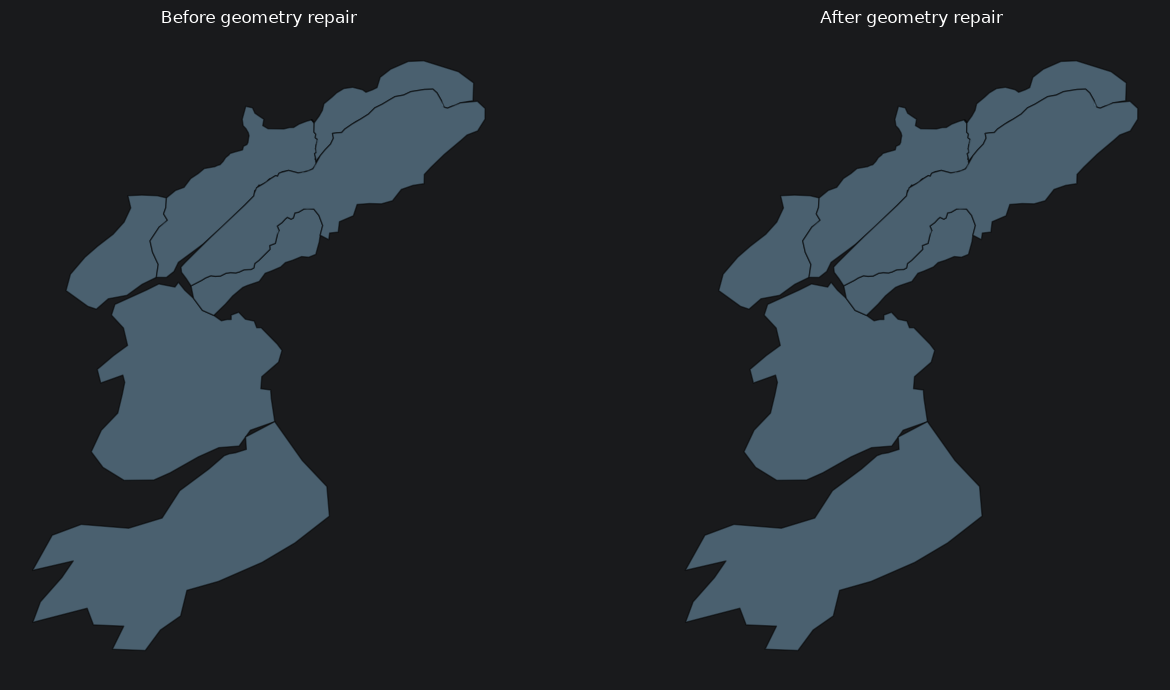

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

ridges_original.plot(
    ax=axes[0],
    facecolor="#7CA6C2",
    edgecolor="black",
    alpha=0.5
)
axes[0].set_title("Before geometry repair")

ridges.plot(
    ax=axes[1],
    facecolor="#7CA6C2",
    edgecolor="black",
    alpha=0.5
)
axes[1].set_title("After geometry repair")

for ax in axes:
    ax.set_axis_off()

plt.tight_layout()
plt.show()

In [37]:
from shapely.geometry import (
    Polygon,
    MultiPolygon,
    GeometryCollection
)
from shapely.ops import unary_union

def extract_polygons(geom):
    if geom.is_empty:
        return geom

    if isinstance(geom, (Polygon, MultiPolygon)):
        return geom

    if isinstance(geom, GeometryCollection):
        polygons = []

        for part in geom.geoms:
            if isinstance(part, Polygon):
                polygons.append(part)
            elif isinstance(part, MultiPolygon):
                polygons.extend(part.geoms)

        if not polygons:
            raise ValueError("No polygonal geometries found")

        return unary_union(polygons)

    raise TypeError(f"Unexpected geometry type: {geom.geom_type}")


ridges["geometry"] = ridges.geometry.apply(extract_polygons)

In [38]:
print(ridges.geometry.geom_type.value_counts())
print("All valid:", ridges.geometry.is_valid.all())
print("All polygonal:", ridges.geometry.geom_type.isin(
    ["Polygon", "MultiPolygon"]
).all())

Polygon    7
Name: count, dtype: int64
All valid: True
All polygonal: True


In [39]:
maydantal = ridges[
    ridges["name"].str.contains("Майдан", case=False, na=False)
]

print("Geometry type:", maydantal.geometry.iloc[0].geom_type)
print("Area:", maydantal.to_crs(32642).area.iloc[0] / 1e6, "km²")

Geometry type: Polygon
Area: 660.6539875840609 km²


In [40]:
from itertools import combinations

ridges_utm = ridges.to_crs("EPSG:32642")

overlaps = []

for i, j in combinations(ridges_utm.index, 2):
    a = ridges_utm.loc[i]
    b = ridges_utm.loc[j]

    intersection = a.geometry.intersection(b.geometry)

    if not intersection.is_empty and intersection.area > 0:
        overlaps.append({
            "ridge_1": a["name"],
            "ridge_2": b["name"],
            "overlap_km2": intersection.area / 1_000_000
        })

overlaps_df = pd.DataFrame(overlaps)

display(
    overlaps_df.sort_values(
        "overlap_km2",
        ascending=False
    ) if not overlaps_df.empty else overlaps_df
)

,ridge_1,ridge_2,overlap_km2
2,Угамский хребет,Пскемский хребет,2.432390
4,Майдантальский хребет,Пскемский хребет,1.274528
3,Коксуйский хребет,Пскемский хребет,1.180531
1,Угамский хребет,Майдантальский хребет,0.785917
0,Каржантау,Угамский хребет,0.545376


In [41]:
peaks_utm = peaks.to_crs("EPSG:32642")
ridges_utm = ridges.to_crs("EPSG:32642")

overlap_results = []

for i, j in combinations(ridges_utm.index, 2):
    a = ridges_utm.loc[i]
    b = ridges_utm.loc[j]

    intersection = a.geometry.intersection(b.geometry)

    if intersection.is_empty or intersection.area == 0:
        continue

    overlapping_peaks = peaks_utm[
        peaks_utm.geometry.intersects(intersection)
    ]

    overlap_results.append({
        "ridge_1": a["name"],
        "ridge_2": b["name"],
        "overlap_km2": round(intersection.area / 1e6, 3),
        "peaks_in_overlap": len(overlapping_peaks)
    })

overlap_peaks_df = pd.DataFrame(overlap_results)

display(overlap_peaks_df)

,ridge_1,ridge_2,overlap_km2,peaks_in_overlap
0,Каржантау,Угамский хребет,0.545,0
1,Угамский хребет,Майдантальский хребет,0.786,0
2,Угамский хребет,Пскемский хребет,2.432,0
3,Коксуйский хребет,Пскемский хребет,1.181,1
4,Майдантальский хребет,Пскемский хребет,1.275,0


In [42]:
name_cols = ["name", "name:ru", "name:en"]

peaks_utm["peak_name"] = (
    peaks_utm.reindex(columns=name_cols)
    .replace(r"^\s*$", pd.NA, regex=True)
    .bfill(axis=1)
    .iloc[:, 0]
    .fillna("Unnamed")
)

In [43]:
ridge_cols = ridges_utm[
    ["id", "name", "geometry"]
].rename(columns={
    "id": "ridge_id",
    "name": "ridge_name"
})

peak_assignments = gpd.sjoin(
    peaks_utm,
    ridge_cols,
    how="left",
    predicate="intersects"
)

# Сколько разных хребтов соответствует каждой вершине
peak_assignments["ridge_count"] = (
    peak_assignments
    .groupby("id")["ridge_id"]
    .transform("nunique")
)

peak_assignments["assignment_status"] = np.select(
    [
        peak_assignments["ridge_count"] == 0,
        peak_assignments["ridge_count"] == 1,
        peak_assignments["ridge_count"] > 1
    ],
    ["UNASSIGNED", "ASSIGNED", "AMBIGUOUS"],
    default="UNKNOWN"
)

display(
    peak_assignments[
        ["id", "peak_name", "ridge_name", "assignment_status"]
    ].head(15)
)

print(
    peak_assignments
    .drop_duplicates(subset=["id", "assignment_status"])
    ["assignment_status"]
    .value_counts()
)

,id,peak_name,ridge_name,assignment_status
0,349004321,Unnamed,Майдантальский хребет,ASSIGNED
1,349004334,Unnamed,Майдантальский хребет,ASSIGNED
2,349004335,Карыкыр,Майдантальский хребет,ASSIGNED
3,349004342,Чатангат,Майдантальский хребет,ASSIGNED
4,349007461,Unnamed,Чаткальский хребет,ASSIGNED
5,349007467,Unnamed,NaN,UNASSIGNED
6,349007476,Unnamed,NaN,UNASSIGNED
7,349007477,Unnamed,Чаткальский хребет,ASSIGNED
8,349007478,Unnamed,Чаткальский хребет,ASSIGNED
9,349007479,Unnamed,Чаткальский хребет,ASSIGNED


assignment_status
ASSIGNED      1287
UNASSIGNED      14
AMBIGUOUS        1
Name: count, dtype: int64


In [18]:
import folium
import geopandas as gpd

# Берём исходные 1302 уникальные вершины
peaks_review = peaks_utm.to_crs(4326).copy()

# Получаем статус каждой вершины
statuses = (
    peak_assignments
    .groupby("id")["assignment_status"]
    .first()
)

peaks_review["assignment_status"] = (
    peaks_review["id"].map(statuses)
)

review_points = peaks_review[
    peaks_review["assignment_status"].isin(
        ["AMBIGUOUS", "UNASSIGNED"]
    )
].copy()

# Карта
m = folium.Map(
    location=[41.8, 70.5],
    zoom_start=9,
    tiles=None
)

folium.TileLayer(
    tiles="https://{s}.tile.opentopomap.org/{z}/{x}/{y}.png",
    attr="© OpenTopoMap, © OpenStreetMap contributors",
    name="OpenTopoMap",
    max_zoom=17
).add_to(m)

# Полигоны хребтов
folium.GeoJson(
    ridges_utm.to_crs(4326),
    name="Ridge polygons",
    style_function=lambda feature: {
        "color": "#416B8A",
        "weight": 2,
        "fillOpacity": 0.10
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["name"],
        aliases=["Ridge:"]
    )
).add_to(m)

# Проблемные вершины
for _, row in review_points.iterrows():
    color = (
        "red"
        if row["assignment_status"] == "AMBIGUOUS"
        else "orange"
    )

    folium.CircleMarker(
        location=[row.geometry.y, row.geometry.x],
        radius=7,
        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=0.9,
        tooltip=(
            f"{row.get('peak_name', 'Unnamed')} | "
            f"{row['elevation_m']:.0f} m | "
            f"{row['assignment_status']} \n",
            f"ID {row['id']}"
        )
    ).add_to(m)

folium.LayerControl().add_to(m)

# Приближаем карту к проблемным точкам
if not review_points.empty:
    minx, miny, maxx, maxy = review_points.total_bounds
    m.fit_bounds([[miny, minx], [maxy, maxx]])

m.save(str(ROOT / "exports" / "ridge_assignment_review.html"))

m

In [44]:
# Одна строка на каждую вершину
assignments = (
    peak_assignments
    .sort_values("ridge_id", na_position="last")
    .drop_duplicates(subset="id")
    .copy()
)

# Сохраняем первоначальные статусы
assignments["original_status"] = assignments["assignment_status"]
assignments["assignment_method"] = "SPATIAL_JOIN"

# Находим ID хребтов
pskem = ridges.loc[
    ridges["name"].str.contains("Пскем", case=False),
    ["id", "name"]
].iloc[0]

chatkal = ridges.loc[
    ridges["name"].str.contains("Чаткал", case=False),
    ["id", "name"]
].iloc[0]

# Ручные назначения
ambiguous = assignments["original_status"] == "AMBIGUOUS"
unassigned = assignments["original_status"] == "UNASSIGNED"

assignments.loc[ambiguous, "ridge_id"] = pskem["id"]
assignments.loc[ambiguous, "ridge_name"] = pskem["name"]

assignments.loc[unassigned, "ridge_id"] = chatkal["id"]
assignments.loc[unassigned, "ridge_name"] = chatkal["name"]

# Обновляем статус
manual = ambiguous | unassigned

assignments.loc[manual, "assignment_status"] = "MANUAL_ASSIGNED"
assignments.loc[manual, "assignment_method"] = "MANUAL_REVIEW"

print(assignments["assignment_status"].value_counts())
print("Total unique peaks:", assignments["id"].nunique())

assignment_status
ASSIGNED           1287
MANUAL_ASSIGNED      15
Name: count, dtype: int64
Total unique peaks: 1302


In [45]:
assert len(assignments) == 1302
assert assignments["id"].nunique() == 1302
assert assignments["ridge_id"].notna().all()

display(
    assignments.groupby("ridge_name")
    .agg(
        peak_count=("id", "count"),
        min_elevation=("elevation_m", "min"),
        median_elevation=("elevation_m", "median"),
        max_elevation=("elevation_m", "max")
    )
    .sort_values("peak_count", ascending=False)
)

,peak_count,min_elevation,median_elevation,max_elevation
ridge_name,,,,
Чаткальский хребет,476,1800.900000,2506.638062,3875.500000
Пскемский хребет,355,1801.362793,3672.817627,4395.500000
Угамский хребет,156,1811.800000,3378.000000,3876.200000
Кураминский хребет,142,1801.300000,2312.546582,3661.596191
Майдантальский хребет,91,2298.200000,3896.307861,4358.400000
Коксуйский хребет,56,1847.314087,2634.040454,3828.000000
Каржантау,26,1812.000000,2211.600000,2823.800000


In [46]:
assignments.to_file(
    PROCESSED / "peaks_with_ridges.gpkg",
    driver="GPKG"
)

assignments[
    [
        "id",
        "peak_name",
        "elevation_m",
        "ridge_id",
        "ridge_name",
        "original_status",
        "assignment_status",
        "assignment_method"
    ]
].to_csv(
    PROCESSED / "ridge_peak_assignments.csv",
    index=False
)

In [47]:
# Обе геометрии в UTM
ridges_utm = ridges.to_crs("EPSG:32642")
boundary_utm = boundary.to_crs("EPSG:32642")

# Обрезаем полигоны по административной границе
ridges_clipped = gpd.clip(
    ridges_utm,
    boundary_utm
)

# Пересчитываем площадь
ridges_clipped["area_km2"] = (
    ridges_clipped.geometry.area / 1e6
)

# Проверяем изменение площади
area_comparison = (
    ridges_utm[["id", "name"]]
    .assign(
        original_area_km2=ridges_utm.geometry.area / 1e6
    )
    .merge(
        ridges_clipped[["id", "area_km2"]],
        on="id"
    )
)

display(area_comparison.round(1))

,id,name,original_area_km2,area_km2
0,1174,Каржантау,780.1,401.6
1,2648,Чаткальский хребет,3267.2,3240.9
2,3636,Кураминский хребет,3939.8,1373.1
3,5973,Угамский хребет,1318.1,716.8
4,16551,Коксуйский хребет,525.3,208.9
5,17744,Майдантальский хребет,660.7,249.6
6,21445,Пскемский хребет,2523.2,1703.7


In [49]:



# Переводим полигоны в метрическую CRS
ridges_stats = ridges_clipped.copy()


# Площадь каждого полигона
ridges_stats["area_km2"] = (
    ridges_stats.geometry.area / 1_000_000
)

# Проверяем, что каждая вершина встречается один раз
assert assignments["id"].is_unique
assert assignments["ridge_id"].notna().all()
assert len(assignments) == 1302

# Подготовим ключи для соединения
ridges_stats["ridge_key"] = (
    ridges_stats["id"].astype("Int64").astype(str)
)

assignments["ridge_key"] = (
    assignments["ridge_id"].astype("Int64").astype(str)
)

In [50]:
print("Ridges keys:")
print(ridges_stats[["id", "ridge_key"]].to_string(index=False))

print("\nAssignments keys:")
print(assignments[["ridge_id", "ridge_key"]].drop_duplicates().to_string(index=False))

print("\nUnmatched keys:")
print(
    set(assignments["ridge_key"])
    - set(ridges_stats["ridge_key"])
)

Ridges keys:
   id ridge_key
 3636      3636
 2648      2648
16551     16551
 1174      1174
 5973      5973
21445     21445
17744     17744

Assignments keys:
 ridge_id ridge_key
   1174.0      1174
   2648.0      2648
   3636.0      3636
   5973.0      5973
  16551.0     16551
  21445.0     21445
  17744.0     17744

Unmatched keys:
set()


In [51]:
peak_stats = (
    assignments
    .groupby("ridge_key")
    .agg(
        peak_count=("id", "nunique"),
        min_elevation=("elevation_m", "min"),
        median_elevation=("elevation_m", "median"),
        mean_elevation=("elevation_m", "mean"),
        max_elevation=("elevation_m", "max"),
        p90_elevation=(
            "elevation_m",
            lambda x: x.quantile(0.90)
        )
    )
    .reset_index()
)

ridge_summary = ridges_stats.merge(
    peak_stats,
    on="ridge_key",
    how="left",
    validate="one_to_one"
)

ridge_summary["peak_density_100km2"] = (
    ridge_summary["peak_count"]
    / ridge_summary["area_km2"]
    * 100
)

cols = [
    "name",
    "area_km2",
    "peak_count",
    "peak_density_100km2",
    "median_elevation",
    "p90_elevation",
    "max_elevation"
]

display(
    ridge_summary[cols]
    .sort_values("peak_count", ascending=False)
    .round(1)
)

,name,area_km2,peak_count,peak_density_100km2,median_elevation,p90_elevation,max_elevation
1,Чаткальский хребет,3240.9,476,14.7,2506.6,3613.3,3875.5
5,Пскемский хребет,1703.7,355,20.8,3672.8,4138.9,4395.5
4,Угамский хребет,716.8,156,21.8,3378.0,3677.5,3876.2
0,Кураминский хребет,1373.1,142,10.3,2312.5,2823.1,3661.6
6,Майдантальский хребет,249.6,91,36.5,3896.3,4198.2,4358.4
2,Коксуйский хребет,208.9,56,26.8,2634.0,3586.9,3828.0
3,Каржантау,401.6,26,6.5,2211.6,2671.4,2823.8


In [52]:
elevation_bands = (
    assignments
    .assign(
        above_3000=lambda df: df["elevation_m"] >= 3000,
        above_4000=lambda df: df["elevation_m"] >= 4000
    )
    .groupby("ridge_key")
    .agg(
        peaks_3000=("above_3000", "sum"),
        peaks_4000=("above_4000", "sum")
    )
    .reset_index()
)

ridge_summary = ridge_summary.merge(
    elevation_bands,
    on="ridge_key",
    how="left",
    validate="one_to_one"
)

ridge_summary["share_3000_pct"] = (
    ridge_summary["peaks_3000"]
    / ridge_summary["peak_count"]
    * 100
)

ridge_summary["share_4000_pct"] = (
    ridge_summary["peaks_4000"]
    / ridge_summary["peak_count"]
    * 100
)

display(
    ridge_summary[
        [
            "name",
            "peak_count",
            "peaks_3000",
            "peaks_4000",
            "share_3000_pct",
            "share_4000_pct"
        ]
    ].sort_values("share_3000_pct", ascending=False).round(1)
)

,name,peak_count,peaks_3000,peaks_4000,share_3000_pct,share_4000_pct
6,Майдантальский хребет,91,87,33,95.6,36.3
5,Пскемский хребет,355,299,83,84.2,23.4
4,Угамский хребет,156,99,0,63.5,0.0
2,Коксуйский хребет,56,18,0,32.1,0.0
1,Чаткальский хребет,476,134,0,28.2,0.0
0,Кураминский хребет,142,10,0,7.0,0.0
3,Каржантау,26,0,0,0.0,0.0


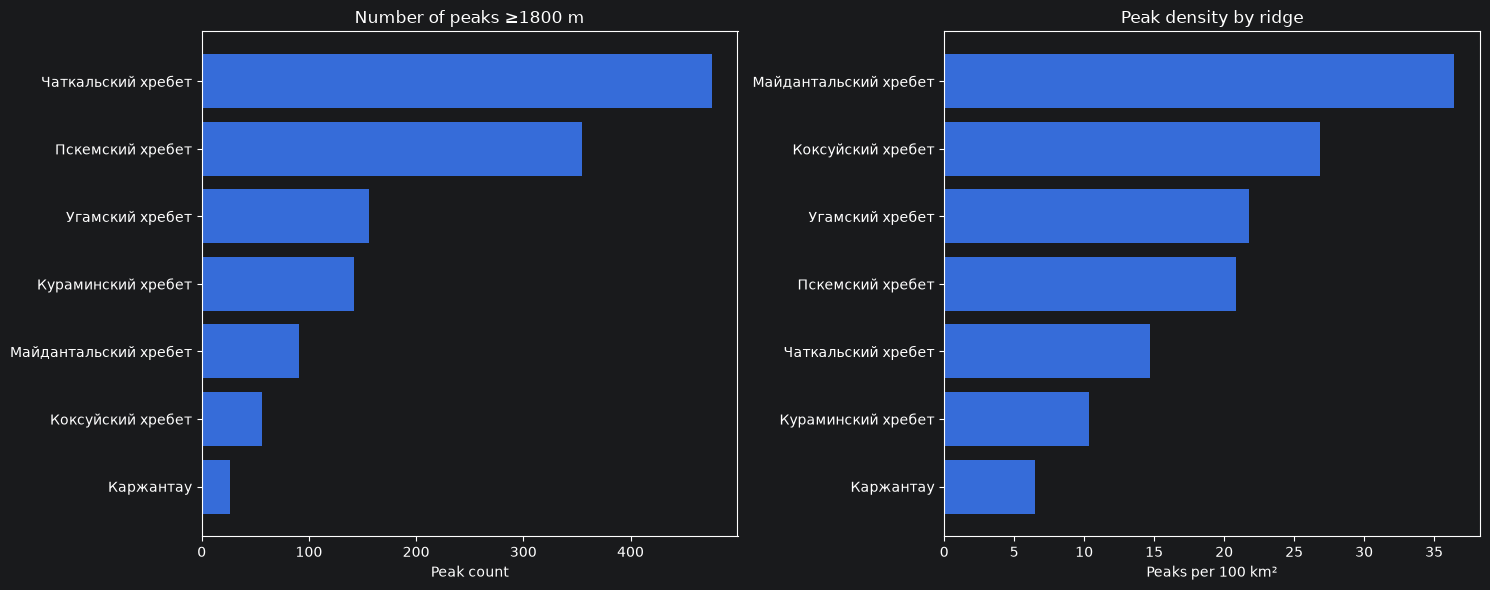

In [53]:

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

df = ridge_summary.sort_values("peak_count")

axes[0].barh(
    df["name"],
    df["peak_count"]
)
axes[0].set_title("Number of peaks ≥1800 m")
axes[0].set_xlabel("Peak count")

df = ridge_summary.sort_values("peak_density_100km2")

axes[1].barh(
    df["name"],
    df["peak_density_100km2"]
)
axes[1].set_title("Peak density by ridge")
axes[1].set_xlabel("Peaks per 100 km²")

plt.tight_layout()
plt.show()

In [54]:
assert len(ridges_stats) == 7
assert ridge_summary["peak_count"].sum() == 1302
assert (ridges_stats["area_km2"] > 0).all()

In [56]:
# Проверяем готовность данных
required = [
    "peak_density_100km2",
    "median_elevation",
    "share_3000_pct"
]

assert ridge_summary[required].notna().all().all()
assert len(ridge_summary) == 7

# Экспорт статистических полигонов
ridge_summary.to_file(
    PROCESSED / "ridges_with_stats.gpkg",
    layer="ridge_statistics",
    driver="GPKG"
)

# Экспорт вершин
assignments.to_file(
    PROCESSED / "peaks_with_ridges.gpkg",
    layer="peaks",
    driver="GPKG"
)

# Административная граница
boundary.to_file(
    PROCESSED / "tashkent_boundary.gpkg",
    driver="GPKG"
)